# AgriLens | Egyptian EMIT + Sentinel-2 — Audited Results

Real field-level integration over one 3 × 3 km Egypt Nile Delta AOI. EMIT L2A: **15 Jun 2025** (60 m); Sentinel-2: **16 Jun 2025** (20 m). **This notebook does not claim crop-stress diagnosis, dust/drought causality, or Satellite 813 processing.**

**Data provenance:** User-provided Earth Engine EMIT export field tables, independently cross-checked for internal integrity; no NASA checksums verified. Predicted FTW field boundaries are not surveyed ground truth. Execute from the package root or `notebooks/` folder.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
root = next(p for p in [Path.cwd(), Path.cwd().parent] if (p/'inputs'/'egypt_hsi_s2_usable_fields.csv').exists())
fields = pd.read_csv(root/'inputs'/'egypt_hsi_s2_usable_fields.csv')
spectra = pd.read_csv(root/'inputs'/'egypt_hsi_complete_spectra.csv')
print('Root:', root)
print('Fields:', fields.shape, 'Spectra:', spectra.shape)


Root: /mnt/data/AgriLens_Egypt_Audited_Handoff
Fields: (14, 25) Spectra: (3248, 6)


## Reproducible integrity checks

All observations used for the spectral figure have complete field–wavelength pairs. The raw 240-channel table still includes eight wavelengths with no valid median in any of the 14 fields; clean spectra omit those channels.

In [2]:
assert fields.field_id.nunique()==14
assert spectra.field_id.nunique()==14
assert spectra.wavelength_nm.nunique()==232
assert spectra.shape[0]==3248
assert spectra.reflectance_median.notna().all()
assert not spectra.duplicated(['field_id','wavelength_nm']).any()
assert (fields.s2_minus_emit_days==1).all()
print('PASS | 14 fields, 232 complete wavelengths, 3248 records, one-day gap')
display(fields.groupby('field_split').agg(n_fields=('field_id','size'),n_emit_pixels=('emit_valid_pixel_count','sum')))


PASS | 14 fields, 232 complete wavelengths, 3248 records, one-day gap


,n_fields,n_emit_pixels
field_split,,
test,5,89
train,3,24
validation,6,100


## Sampling / legacy split audit

Use `field_split` from audited geometry; `s2_split_recorded` is a historical split that disagrees for most matched fields. Flag fields with fewer than 5 valid EMIT pixels or under 50% quality coverage (a sensitivity criterion, **not** a calibrated scientific threshold).

In [3]:
flags=fields.copy()
flags['coverage_review']=(flags.emit_valid_pixel_count<5)|(flags.emit_quality_coverage_fraction<.5)
print('Legacy split conflicts:', int((flags.field_split!=flags.s2_split_recorded).sum()))
display(flags[['field_id','field_split','s2_split_recorded','emit_valid_pixel_count','emit_quality_coverage_fraction','coverage_review']])


Legacy split conflicts: 10


,field_id,field_split,s2_split_recorded,emit_valid_pixel_count,emit_quality_coverage_fraction,coverage_review
0,1664782,train,train,14,0.933333,False
1,1664803,train,train,7,0.466667,True
2,1664833,validation,train,6,1.000000,False
3,1664841,validation,train,6,1.000000,False
4,1664845,validation,test,8,1.000000,False
5,1664850,train,test,3,0.088235,True
6,1664863,validation,test,19,0.730769,False
7,1664865,validation,test,49,1.000000,False
8,1664867,validation,test,12,1.000000,False
9,1664893,test,test,7,1.000000,False


## Spectral signatures over Egyptian FTW-predicted fields

These are **field median reflectances**, not healthy-versus-stressed labels. Discontinuities in the wavelength coverage are left blank.

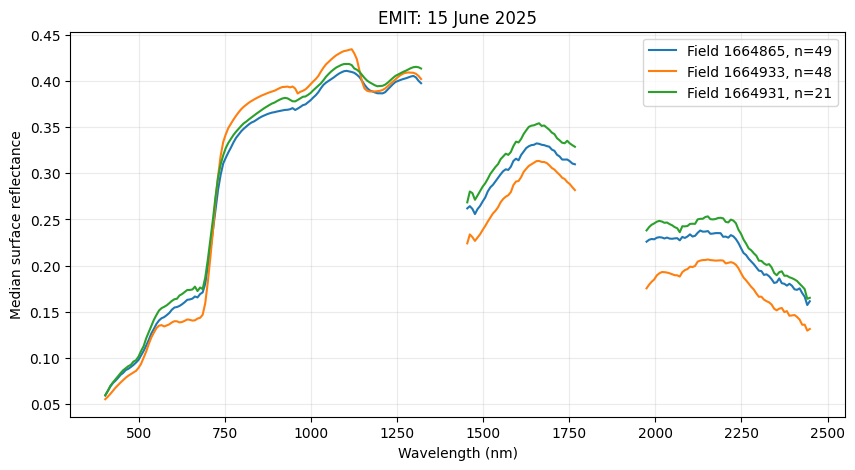

In [4]:
fig, ax=plt.subplots(figsize=(10,5))
for row in fields.nlargest(3,'emit_valid_pixel_count').itertuples():
 d=spectra[spectra.field_id==row.field_id].sort_values('wavelength_nm')
 x=d.wavelength_nm.to_numpy(); y=d.reflectance_median.to_numpy()
 for pos in np.where(np.diff(x)>20)[0][::-1]:
  x=np.insert(x,pos+1,np.nan);y=np.insert(y,pos+1,np.nan)
 ax.plot(x,y,label=f'Field {row.field_id}, n={row.emit_valid_pixel_count}')
ax.set(xlabel='Wavelength (nm)',ylabel='Median surface reflectance',title='EMIT: 15 June 2025')
ax.legend();ax.grid(alpha=.25);plt.show()


## Cross-sensor NDVI comparison

Mean Sentinel-2 field NDVI versus median EMIT field NDVI, **one day apart** with **different resolutions and sensor bandpasses**. Correlation or absolute disagreement cannot be interpreted as accuracy without external reference data.

Descriptive Pearson r = 0.743; mean absolute index difference = 0.0445


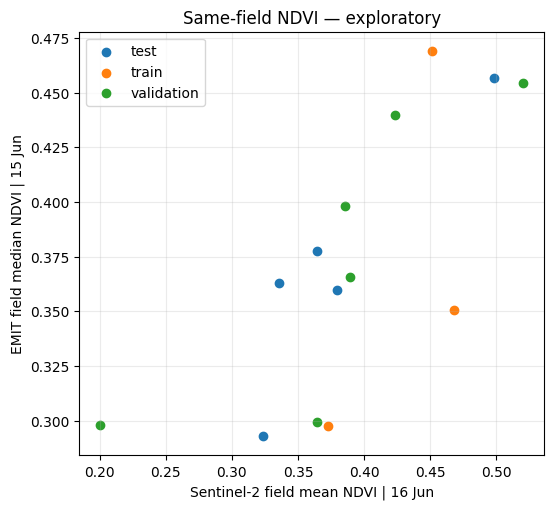

In [5]:
r=fields.emit_ndvi_median.corr(fields.s2_ndvi_mean)
mae=(fields.emit_ndvi_median-fields.s2_ndvi_mean).abs().mean()
print(f'Descriptive Pearson r = {r:.3f}; mean absolute index difference = {mae:.4f}')
fig,ax=plt.subplots(figsize=(6,5.5))
for split,g in fields.groupby('field_split'):
 ax.scatter(g.s2_ndvi_mean,g.emit_ndvi_median,label=split)
ax.set(xlabel='Sentinel-2 field mean NDVI | 16 Jun',ylabel='EMIT field median NDVI | 15 Jun',title='Same-field NDVI — exploratory')
ax.legend();ax.grid(alpha=.25);plt.show()


## Scientific boundaries / next steps

- Environmental columns (dust, aerosol, modeled root-zone moisture and precipitation) are constant across all matched fields on 16 June 2025. They **cannot** support cross-field causal stress classification from this sample.
- Geographic split among matched fields is **3 train / 6 validation / 5 test**; the stricter high-coverage sensitivity subset has only **one** training field. Do not train a 232-feature supervised classifier on this sample.
- Field polygons are predicted and can overlap the EMIT sampling grid imperfectly; some fields contain mixed land-cover pixels.
- For an independent raw-data QA, obtain original EMIT L2A reflectance / mask / uncertainty granule with matching ID and checksum; this package includes only analysis outputs.
- AgriLens can demonstrate **same-AOI Egyptian hyperspectral spectral processing**, field alignment, indices and exploratory NDVI monitoring. A dust/drought diagnostic model requires independent labels and independent temporal replicates.
